# Person C: Clustering and Generalization to New People

**Research question 3:** What structure exists in the data without labels,
and how well does an activity model work for people it has never seen?

**Sections**
1. Setup and data loading
2. Clustering without labels (k-means, Gaussian mixture, agglomerative)
3. Generalization to new people (accuracy for each test person and
   leave-one-person-out cross-validation)
4. Leakage experiment: random split vs. person-based split
5. Summary

The optional deep learning experiment (1D CNN on the raw signals) is in
`C_cnn_raw_signals.ipynb`.

**Model.** Sections 3 and 4 use Person A's best model (standardized linear
SVM, `C = 0.1`) so the results can be compared across the report.

## 1. Setup and data loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, adjusted_rand_score, f1_score,
                             silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import (GroupShuffleSplit, LeaveOneGroupOut,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# Make the shared src/ folder importable from notebooks/
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.har_data import ACTIVITY_NAMES, load_features
from src.evaluation import RANDOM_STATE, save_figure, save_results

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)

data = load_features()
X_train = data.X_train
y_train = data.y_train.ravel()
labels = [ACTIVITY_NAMES[i] for i in sorted(ACTIVITY_NAMES)]

print("Training data:", data.X_train.shape)
print("Testing data:", data.X_test.shape)
print("Number of features:", len(data.feature_names))
print("Number of activities:", len(set(y_train)))

Training data: (7352, 561)
Testing data: (2947, 561)
Number of features: 561
Number of activities: 6


In [2]:
def best_model():
    """Return a fresh copy of Person A's best model (tuned linear SVM)."""
    return make_pipeline(
        StandardScaler(),
        LinearSVC(C=0.1, max_iter=10000, random_state=RANDOM_STATE),
    )

## 2. Clustering without labels

Clustering ignores the activity labels and asks whether the windows fall
into natural groups. Features are standardized first (they have different
ranges), then reduced with PCA to the components that keep 95% of the
variance, which removes redundant features and speeds up clustering.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

print("Original shape:", X_train.shape)
print("Standardized shape:", X_scaled.shape)
print("Mean:", X_scaled.mean().round(4))
print("Standard deviation:", X_scaled.std().round(4))

Original shape: (7352, 561)
Standardized shape: (7352, 561)
Mean: 0.0
Standard deviation: 1.0


In [4]:
# PCA: keep enough components for 95% of the variance
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Number of principal components:", X_pca.shape[1])
print("Variance retained:", round(sum(pca.explained_variance_ratio_), 4))
print("New dataset shape:", X_pca.shape)

Original number of features: 561
Number of principal components: 102
Variance retained: 0.9508
New dataset shape: (7352, 102)


### 2.1 Choosing k: elbow method and silhouette score

* **Inertia** (elbow method): total squared distance from each point to its
  cluster center. It always falls as k grows; we look for the bend.
* **Silhouette score**: how much closer each point is to its own cluster
  than to the next one (from -1 to 1, higher is better). Computed on a
  random sample of 2,000 windows to keep it fast.

In [5]:
k_values = list(range(2, 11))
inertia_values = []
silhouette_values = []

# Run k-means for each k
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    cluster_labels = kmeans.fit_predict(X_pca)
    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(X_pca, cluster_labels, sample_size=2000,
                             random_state=RANDOM_STATE)
    silhouette_values.append(score)
    print(f"k={k}: inertia={kmeans.inertia_:,.0f}, silhouette={score:.4f}")

k_selection = pd.DataFrame({"k": k_values, "inertia": inertia_values,
                            "silhouette": silhouette_values})
save_results(k_selection.set_index("k"), "C_kmeans_k_selection")

k=2: inertia=2,133,134, silhouette=0.4182


k=3: inertia=1,878,867, silhouette=0.3465


k=4: inertia=1,773,542, silhouette=0.1757


k=5: inertia=1,672,341, silhouette=0.1455


k=6: inertia=1,616,137, silhouette=0.1217


k=7: inertia=1,574,488, silhouette=0.0918


k=8: inertia=1,533,302, silhouette=0.0977


k=9: inertia=1,493,943, silhouette=0.0936
k=10: inertia=1,456,334, silhouette=0.0984


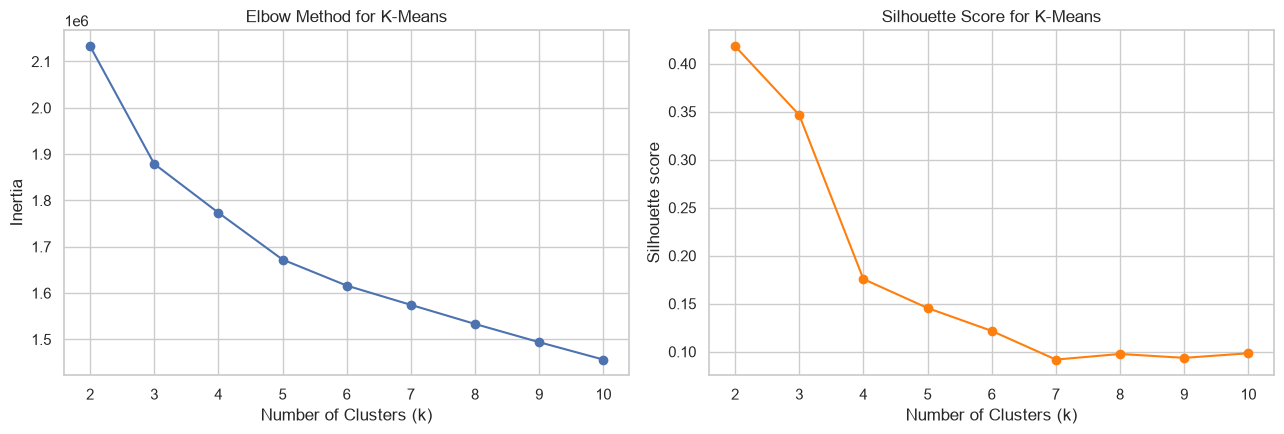

In [6]:
# Elbow method and silhouette score side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, inertia_values, marker="o")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method for K-Means")
axes[0].set_xticks(k_values)

axes[1].plot(k_values, silhouette_values, marker="o", color="tab:orange")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette Score for K-Means")
axes[1].set_xticks(k_values)

fig.tight_layout()
save_figure(fig, "C_elbow_silhouette")
plt.show()

**Observations.** The elbow curve has no sharp bend, but it flattens after k = 3. The silhouette score is clearly highest at **k = 2 (0.418)**, followed by k = 3 (0.347), and it drops below 0.18 for k ≥ 4. Without labels, the data most naturally splits into **two** groups, not six.

### 2.2 Comparing clusters with the true activities

The **adjusted Rand index (ARI)** measures how well the clusters match the
true labels (1 = perfect match, 0 = no better than random). We test k = 2,
the best k by silhouette, and k = 6, the number of activities. For k = 2 we
also compare against a **moving vs. still** labeling (walking, upstairs and
downstairs vs. sitting, standing and lying).

In [7]:
# Moving (activities 1-3) = 0, still (activities 4-6) = 1
y_train_binary = np.where(y_train <= 3, 0, 1)
cluster_rows = []


def record(method, k, cluster_labels):
    '''Store ARI and silhouette for one clustering result and print them.'''
    row = {
        "method": method,
        "k": k,
        "ari_6_activities": adjusted_rand_score(y_train, cluster_labels),
        "ari_moving_vs_still": adjusted_rand_score(y_train_binary,
                                                   cluster_labels),
        "silhouette": silhouette_score(X_pca, cluster_labels,
                                       sample_size=2000,
                                       random_state=RANDOM_STATE),
    }
    cluster_rows.append(row)
    print(f"{method} k={k}: ARI={row['ari_6_activities']:.4f}, "
          f"moving vs. still ARI={row['ari_moving_vs_still']:.4f}, "
          f"silhouette={row['silhouette']:.4f}")

In [8]:
# K-Means
for k in [2, 6]:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    record("K-Means", k, kmeans.fit_predict(X_pca))

K-Means k=2: ARI=0.3285, moving vs. still ARI=0.9891, silhouette=0.4182
K-Means k=6: ARI=0.4196, moving vs. still ARI=0.3893, silhouette=0.1217


In [9]:
# Gaussian Mixture Model
for k in [2, 6]:
    gmm = GaussianMixture(n_components=k, random_state=RANDOM_STATE,
                          n_init=3)
    record("Gaussian Mixture", k, gmm.fit_predict(X_pca))

Gaussian Mixture k=2: ARI=0.3122, moving vs. still ARI=0.9368, silhouette=0.4061


Gaussian Mixture k=6: ARI=0.3090, moving vs. still ARI=0.4578, silhouette=0.1120


In [10]:
# Agglomerative clustering (Ward linkage)
for k in [2, 6]:
    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    agg_labels = agg.fit_predict(X_pca)
    record("Agglomerative", k, agg_labels)
# agg_labels now holds the k = 6 agglomerative clusters, used in 2.3

Agglomerative k=2: ARI=0.3319, moving vs. still ARI=0.9995, silhouette=0.4180


Agglomerative k=6: ARI=0.4744, moving vs. still ARI=0.4384, silhouette=0.1187


,method,k,ari_6_activities,ari_moving_vs_still,silhouette
0,K-Means,2,0.3285,0.9891,0.4182
1,K-Means,6,0.4196,0.3893,0.1217
2,Gaussian Mixture,2,0.3122,0.9368,0.4061
3,Gaussian Mixture,6,0.3090,0.4578,0.1120
4,Agglomerative,2,0.3319,0.9995,0.4180
5,Agglomerative,6,0.4744,0.4384,0.1187


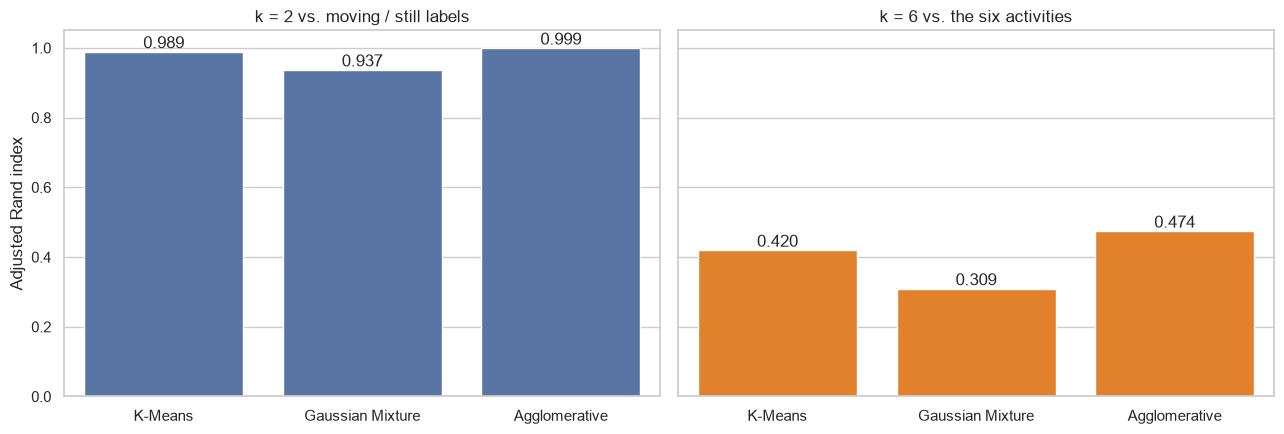

In [11]:
cluster_results = pd.DataFrame(cluster_rows)
save_results(cluster_results.set_index(["method", "k"]),
             "C_clustering_comparison")
display(cluster_results)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
sns.barplot(data=cluster_results[cluster_results["k"] == 2], x="method",
            y="ari_moving_vs_still", ax=axes[0])
axes[0].set_title("k = 2 vs. moving / still labels")
sns.barplot(data=cluster_results[cluster_results["k"] == 6], x="method",
            y="ari_6_activities", ax=axes[1], color="tab:orange")
axes[1].set_title("k = 6 vs. the six activities")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("Adjusted Rand index")
    ax.set_ylim(0, 1.05)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f")
fig.tight_layout()
save_figure(fig, "C_clustering_comparison")
plt.show()

**Observations.**

* **k = 2 finds "moving vs. still" almost perfectly.** Compared with the moving/still labels, the ARI is 0.9995 for agglomerative clustering, 0.989 for k-means and 0.937 for the Gaussian mixture. So the biggest structure in the data, found with no labels at all, is whether the person is moving.
* **k = 6 does not recover the six activities.** The best ARI is 0.474 (agglomerative), then 0.420 (k-means) and 0.309 (Gaussian mixture). The fine distinctions between activities are not the main structure in the data, which is why supervised classifiers are needed for them.
* Agglomerative clustering with Ward linkage is the best method at both k = 2 and k = 6.

### 2.3 Interpreting the clusters

Which activities end up in the same cluster? The table counts training
windows for each true activity (rows) in each agglomerative cluster with
k = 6 (columns).

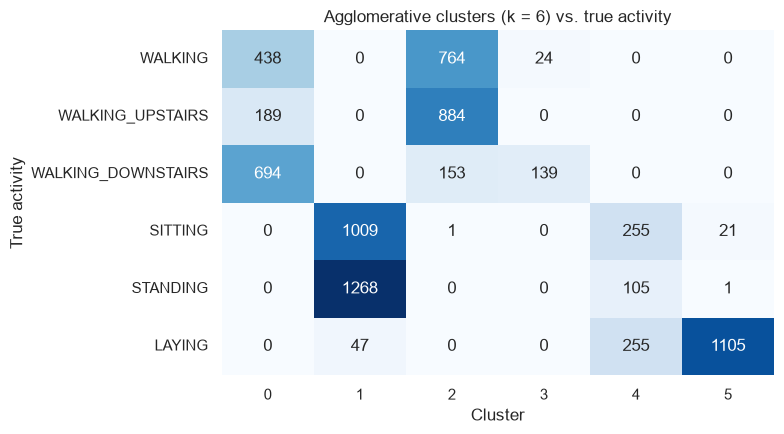

In [12]:
cluster_table = pd.crosstab(
    pd.Series(y_train).map(ACTIVITY_NAMES).rename("True activity"),
    pd.Series(agg_labels, name="Cluster"),
).reindex(labels)
save_results(cluster_table, "C_cluster_vs_activity")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(cluster_table, annot=True, fmt="d", cmap="Blues", cbar=False,
            ax=ax)
ax.set_title("Agglomerative clusters (k = 6) vs. true activity")
fig.tight_layout()
save_figure(fig, "C_cluster_vs_activity")
plt.show()

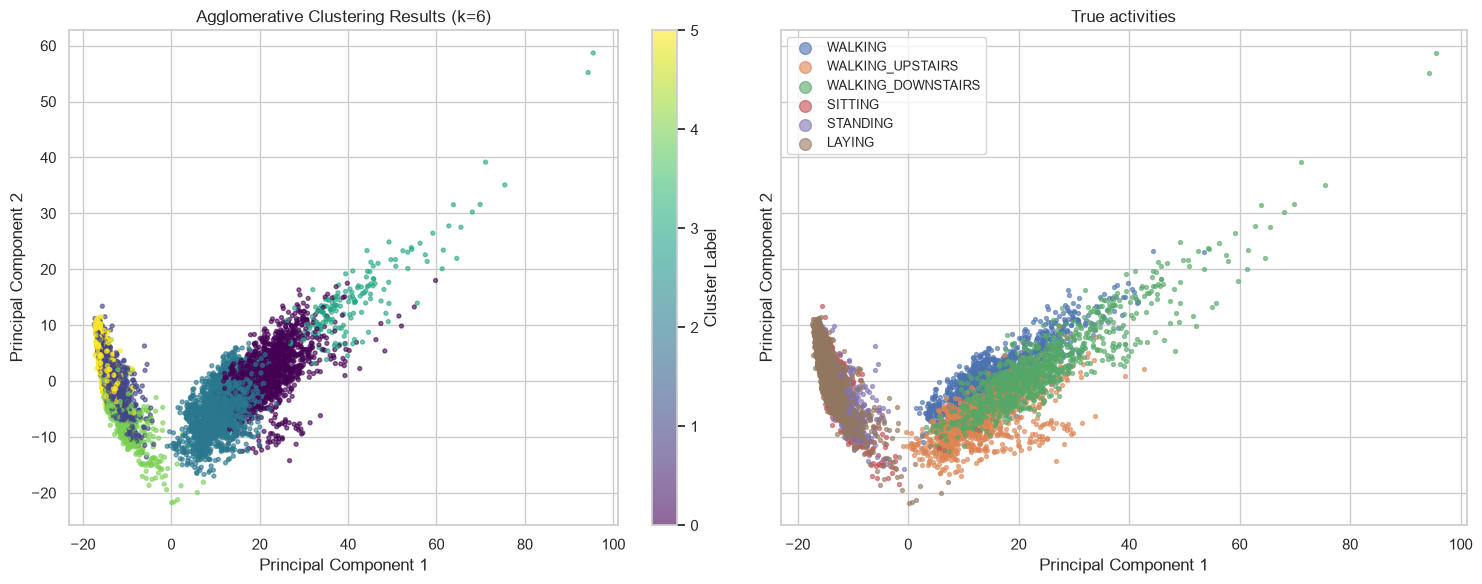

In [13]:
# PCA scatter plot: clusters (left) vs. true activities (right)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels,
                          cmap="viridis", s=8, alpha=0.6)
axes[0].set_title("Agglomerative Clustering Results (k=6)")
fig.colorbar(scatter, ax=axes[0], label="Cluster Label")

for code_, name in ACTIVITY_NAMES.items():
    mask = y_train == code_
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=8, alpha=0.6,
                    label=name)
axes[1].set_title("True activities")
axes[1].legend(markerscale=3, fontsize=9)

for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
fig.tight_layout()
save_figure(fig, "C_cluster_pca_scatter")
plt.show()

**Observations.** The table shows which activities merge:

* **Sitting and standing merge.** Cluster 1 holds 1,009 sitting and 1,268 standing windows. This is the same pair that the classifiers confuse most (Person A's error analysis). Even without labels, the two postures look almost the same to the phone.
* **The three walking activities mix.** Cluster 2 is mostly walking (764) and walking upstairs (884). Cluster 0 is mostly walking downstairs (694) but also contains walking (438) and upstairs (189).
* **Lying is the most distinct still activity.** 1,105 of 1,407 lying windows form their own cluster (5), because the phone is horizontal and gravity points in a different direction.
* In the PCA plot, the first component separates moving from still (the two large clouds). The activities within each cloud overlap heavily.

## 3. Generalization to new people

The official split puts 21 people in training and 9 different people in
the test set, so the test score measures accuracy on **people the model
has never seen**.

In [14]:
print("Training subjects:", sorted(set(data.subject_train.tolist())))
print("Testing subjects:", sorted(set(data.subject_test.tolist())))
print("Number of training subjects:", len(set(data.subject_train)))
print("Number of testing subjects:", len(set(data.subject_test)))

Training subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Testing subjects: [2, 4, 9, 10, 12, 13, 18, 20, 24]
Number of training subjects: 21
Number of testing subjects: 9


In [15]:
model = best_model()
model.fit(data.X_train, data.y_train)

# Testing on the 9 unseen subjects
y_pred = model.predict(data.X_test)
print("Test Accuracy:", round(accuracy_score(data.y_test, y_pred), 4))
print("Test macro F1:",
      round(f1_score(data.y_test, y_pred, average="macro"), 4))

Test Accuracy: 0.962
Test macro F1: 0.9629


,Accuracy,Windows,Most common error
Subject,,,
2,0.9868,302,SITTING -> STANDING
4,0.9685,317,SITTING -> STANDING
9,0.9028,288,SITTING -> STANDING
10,0.8537,294,SITTING -> STANDING
12,0.9688,320,SITTING -> STANDING
13,0.9939,327,WALKING_DOWNSTAIRS -> WALKING
18,0.9835,364,WALKING_DOWNSTAIRS -> WALKING_UPSTAIRS
20,0.9774,354,SITTING -> STANDING
24,0.9974,381,STANDING -> SITTING


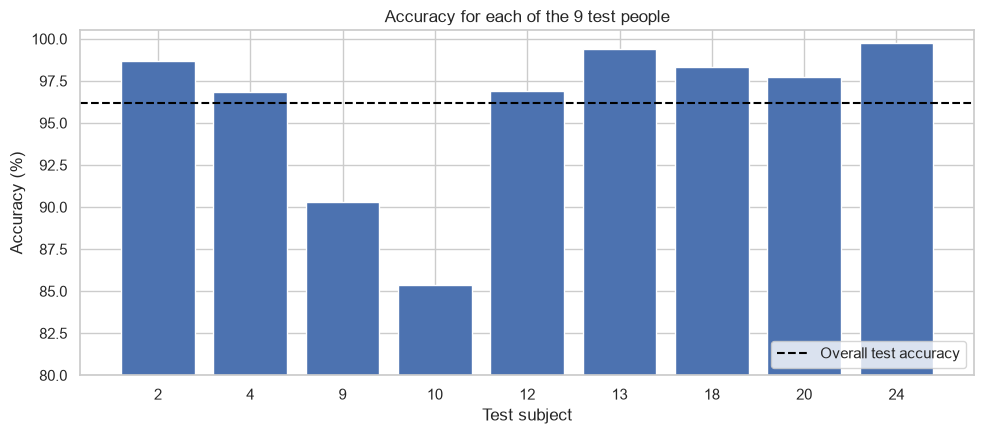

In [16]:
subject_results = pd.DataFrame({
    "Subject": data.subject_test,
    "True Label": data.y_test,
    "Predicted Label": y_pred,
})
subject_results["Correct"] = (
    subject_results["True Label"] == subject_results["Predicted Label"]
)

accuracy_by_subject = (subject_results.groupby("Subject")["Correct"].mean()
                       .rename("Accuracy").to_frame())
accuracy_by_subject["Windows"] = subject_results.groupby("Subject").size()

# Which activity does each weak subject get wrong?
errors = subject_results[~subject_results["Correct"]]
pair_counts = (errors["True Label"].map(ACTIVITY_NAMES) + " -> "
               + errors["Predicted Label"].map(ACTIVITY_NAMES))
accuracy_by_subject["Most common error"] = (
    pair_counts.groupby(errors["Subject"]).agg(
        lambda s: s.value_counts().index[0]))
save_results(accuracy_by_subject, "C_per_subject_test")
display(accuracy_by_subject)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(accuracy_by_subject.index.astype(str),
       accuracy_by_subject["Accuracy"] * 100)
ax.axhline(accuracy_score(data.y_test, y_pred) * 100, linestyle="--",
           color="black", label="Overall test accuracy")
ax.set_ylim(80, 100.5)
ax.set_xlabel("Test subject")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy for each of the 9 test people")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "C_per_subject_test")
plt.show()

**Observations.** Overall test accuracy is 96.2% (macro F1 0.963), but it varies a lot by person, from **85.4% (subject 10) and 90.3% (subject 9) to 99.7% (subject 24)**. For 6 of the 9 people, the most common error is **sitting predicted as standing**. A model that looks excellent on average can still be noticeably worse for particular users.

### 3.1 Leave-one-person-out cross-validation

To see the spread across more people, we train on 20 of the 21 training
people and test on the one left out, for each of the 21 people.

In [17]:
logo = LeaveOneGroupOut()
loso_records = []

for train_idx, test_idx in logo.split(data.X_train, data.y_train,
                                      groups=data.subject_train):
    # Training data: all subjects except the one being left out
    X_train_fold = data.X_train.iloc[train_idx]
    y_train_fold = data.y_train[train_idx]

    # Testing data: the subject being left out
    X_test_fold = data.X_train.iloc[test_idx]
    y_test_fold = data.y_train[test_idx]

    model_fold = best_model().fit(X_train_fold, y_train_fold)
    predictions = model_fold.predict(X_test_fold)

    loso_records.append({
        "Subject": data.subject_train[test_idx][0],
        "Accuracy": accuracy_score(y_test_fold, predictions),
        "Macro F1": f1_score(y_test_fold, predictions, average="macro"),
    })

loso_df = pd.DataFrame(loso_records)
save_results(loso_df.set_index("Subject"), "C_loso")
print(loso_df.round(4).to_string(index=False))
print("\nMean LOSO Accuracy:", round(loso_df["Accuracy"].mean(), 4))
print("Std LOSO Accuracy:", round(loso_df["Accuracy"].std(), 4))
print("Worst subject:",
      loso_df.loc[loso_df["Accuracy"].idxmin()].round(4).to_dict())

 Subject  Accuracy  Macro F1
       1    0.9942    0.9931
       3    0.9824    0.9817
       5    0.9040    0.8998
       6    0.8554    0.8311
       7    0.9091    0.9068
       8    0.9609    0.9592
      11    0.9968    0.9967
      14    0.6873    0.6108
      15    0.9939    0.9940
      16    0.7678    0.7954
      17    0.9783    0.9808
      19    0.9333    0.9252
      21    0.9730    0.9788
      22    0.9907    0.9891
      23    0.9677    0.9678
      25    0.9584    0.9559
      26    0.9923    0.9934
      27    0.9840    0.9867
      28    0.9293    0.9366
      29    0.9855    0.9867
      30    0.9922    0.9917

Mean LOSO Accuracy: 0.9398
Std LOSO Accuracy: 0.0807
Worst subject: {'Subject': 14.0, 'Accuracy': 0.6873, 'Macro F1': 0.6108}


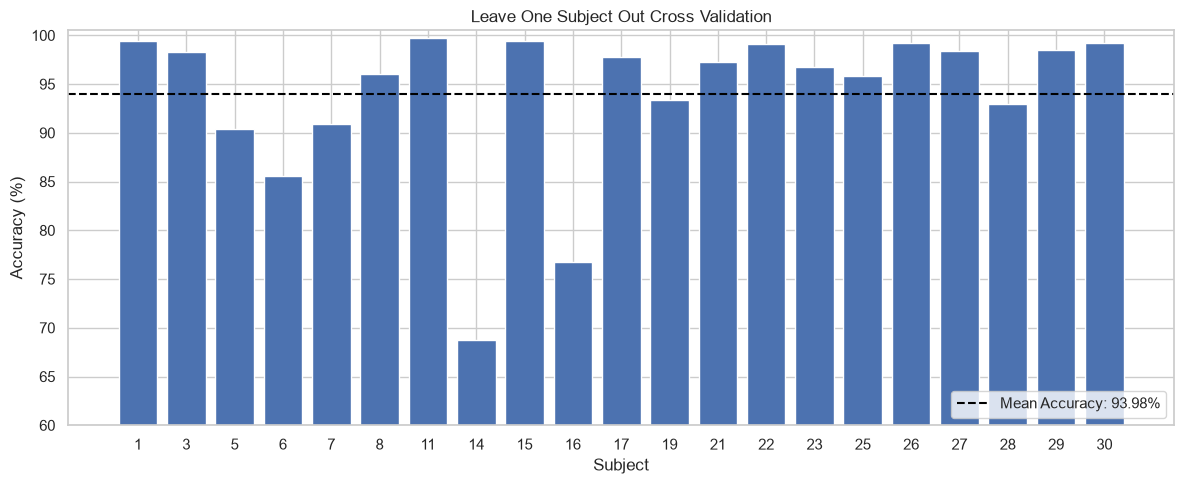

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(loso_df["Subject"].astype(str), loso_df["Accuracy"] * 100)
ax.axhline(
    y=loso_df["Accuracy"].mean() * 100, linestyle="--", color="black",
    label=f"Mean Accuracy: {loso_df['Accuracy'].mean() * 100:.2f}%",
)
ax.set_ylim(60, 100.5)
ax.set_xlabel("Subject")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Leave One Subject Out Cross Validation")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "C_loso")
plt.show()

**Observations.** Leave-one-person-out gives a mean accuracy of **94.0%**, but with a large spread (standard deviation 8.1 points). Most people are above 90%, but **subject 14 drops to 68.7%** and **subject 16 to 76.8%**. Their errors are different. Subject 14's walking and walking downstairs are mostly predicted as walking upstairs, perhaps because of a different gait or a different way of carrying the phone. Subject 16's errors are mostly standing predicted as sitting. To deploy this model, the app would need a short calibration step for each new user, or training data from many more people.

## 4. Leakage experiment: random split vs. person-based split

Many published HAR results split the windows **randomly**. Then the same
person appears in both training and test data, and the model can
recognize *the person's* movement style instead of the activity.
Neighbouring windows also overlap by 50% in this dataset, so a random split
puts near-copies of test windows into the training set.

We pool all 10,299 windows from the 30 people and compare two ways of
holding out 30%:

* **Random split**: 30% of windows at random (stratified by activity).
* **Person-based split**: 30% of the *people* (`GroupShuffleSplit`), so no
  person appears on both sides.

Each split is repeated with 5 different seeds. We test two models: the
linear SVM, and a 5-nearest-neighbors classifier, which works by
memorizing training examples and should be the most affected.

In [19]:
X_all = pd.concat([data.X_train, data.X_test], ignore_index=True)
y_all = np.concatenate([data.y_train, data.y_test])
subjects_all = np.concatenate([data.subject_train, data.subject_test])

leak_models = {
    "Linear SVM": best_model,
    "5-NN": lambda: make_pipeline(StandardScaler(),
                                  KNeighborsClassifier(n_neighbors=5)),
}
leak_rows = []
for seed in range(5):
    random_idx = train_test_split(
        np.arange(len(y_all)), test_size=0.3, stratify=y_all,
        random_state=RANDOM_STATE + seed)
    person_idx = next(GroupShuffleSplit(
        n_splits=1, test_size=0.3, random_state=RANDOM_STATE + seed
    ).split(X_all, y_all, groups=subjects_all))

    for split_name, (tr, te) in {"Random split": random_idx,
                                 "Person-based split": person_idx}.items():
        shared = len(set(subjects_all[tr]) & set(subjects_all[te]))
        for model_name, make_model in leak_models.items():
            fitted = make_model().fit(X_all.iloc[tr], y_all[tr])
            pred = fitted.predict(X_all.iloc[te])
            leak_rows.append({
                "split": split_name, "model": model_name, "seed": seed,
                "people_in_both": shared,
                "accuracy": accuracy_score(y_all[te], pred),
                "f1_macro": f1_score(y_all[te], pred, average="macro"),
            })

leak = pd.DataFrame(leak_rows)
leak_summary = (leak.groupby(["model", "split"])[["accuracy", "f1_macro"]]
                .agg(["mean", "std"]))
leak_summary.columns = ["accuracy", "accuracy_std", "f1_macro",
                        "f1_macro_std"]
save_results(leak, "C_leakage_runs")
save_results(leak_summary, "C_leakage")
display(leak_summary)

inflation = (leak_summary.xs("Random split", level="split")["f1_macro"]
             - leak_summary.xs("Person-based split", level="split")[
                 "f1_macro"])
print("Macro F1 inflation from the random split (points):")
print((inflation * 100).round(2).to_string())
print("People shared between train and test, random split:",
      leak.query("split == 'Random split'")["people_in_both"].iloc[0])

accuracy  accuracy_std  f1_macro  f1_macro_std
model      split                                                             
5-NN       Person-based split    0.8655        0.0249    0.8642        0.0234
           Random split          0.9593        0.0030    0.9608        0.0031
Linear SVM Person-based split    0.9353        0.0335    0.9370        0.0307
           Random split          0.9839        0.0011    0.9849        0.0011

Macro F1 inflation from the random split (points):
model
5-NN          9.66
Linear SVM    4.78
People shared between train and test, random split: 30


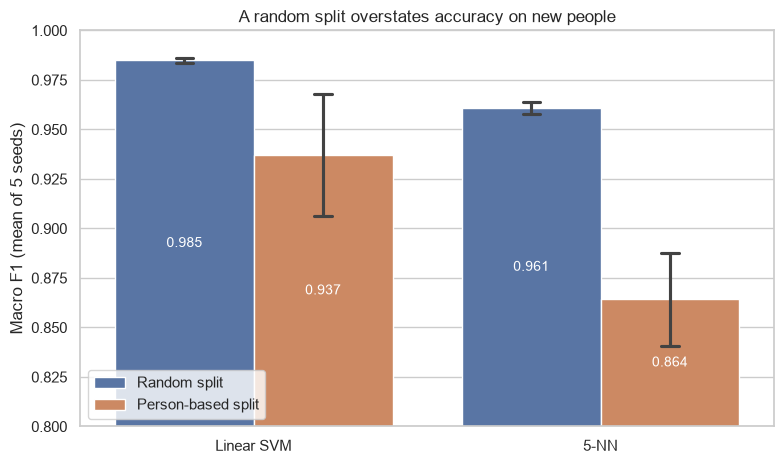

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.barplot(data=leak, x="model", y="f1_macro", hue="split",
            hue_order=["Random split", "Person-based split"],
            errorbar="sd", capsize=0.1, ax=ax)
ax.set_ylim(0.8, 1.0)
ax.set_xlabel("")
ax.set_ylabel("Macro F1 (mean of 5 seeds)")
ax.set_title("A random split overstates accuracy on new people")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", label_type="center",
                 color="white", fontsize=10)
ax.legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "C_leakage")
plt.show()

**Observations.** The random split **overstates performance** for both models:

| Model | Random split | Person-based split | Inflation |
|---|---|---|---|
| Linear SVM | 0.985 | 0.937 ± 0.031 | +4.8 points |
| 5-NN | 0.961 | 0.864 ± 0.023 | +9.7 points |

With a random split, all 30 people appear in both training and test. The model can then match new windows to nearly identical windows from the same person (neighbouring windows overlap by 50%). The k-nearest-neighbors model, which classifies by finding the most similar stored examples, benefits the most. The random split also hides how much results vary between people: the standard deviation is about 0.1 to 0.3 points for the random split but 2 to 3 points for the person-based split. **Results on this dataset are only meaningful if the test people are different from the training people.** This is why the whole project uses the official person-based split and `GroupKFold`.

## 5. Summary

1. **Without labels, the data splits into moving vs. still.** With k = 2, clustering matches this almost perfectly (ARI up to 0.9995). With k = 6 it recovers the six activities only partly (best ARI 0.474). Sitting and standing merge into one cluster, and the three walking activities mix.
2. **Accuracy depends on the person.** On the 9 test people, accuracy ranges from 85.4% to 99.7%. In leave-one-person-out cross-validation it ranges from 68.7% to 99.7% (mean 94.0%). The weak cases are mostly sitting vs. standing, plus one person whose walking was read as walking upstairs.
3. **Splitting by person matters.** A random split inflates macro F1 by 4.8 points for the linear SVM and 9.7 points for 5-NN. Reported accuracies near 98 to 99% on this dataset often come from random splits.
4. The CNN experiment on the raw signals is in `C_cnn_raw_signals.ipynb`.